# Seeing a photograph as a sum of waves
### A 2D FFT demo: checkerboards, phase–power colour, and gradual reconstruction

Run the cells from top to bottom. This notebook generates **400 px squares**, **100 px squares**,
and **0.5 × each checkerboard**, then repeats the analysis for a greyscale photograph.
Eight following cells reconstruct the photo through successively wider windows centred on zero frequency.

**Start here:** change `PHOTO_PATH` in the settings cell to use your own photograph. Leave it as `None`
to use the embedded 512 × 512 sample. You can also supply checkerboard images through `CHECKER_PATHS`.
No image download or scikit-image installation is needed when running this notebook.

Each FFT view has three forms:

| View | What it encodes |
|---|---|
| Greyscale | Normalised log₁₀ power: stronger coefficients are brighter. |
| CET cyclic colour | Phase, from −π to +π; these two ends have the same colour. |
| Multiply blend | Phase RGB colour multiplied by log-power brightness. |

The colour image is a visualisation. The inverse FFT uses the saved **complex coefficients**, with
their full numerical precision. This is an original demonstration of progressive frequency-window
reconstruction, in the style requested; it does not reproduce a particular textbook figure.

In [22]:
# If needed, uncomment and run this line in your Jupyter environment:
# %pip install numpy matplotlib pillow colorcet
# Optional slider near the end: %pip install ipywidgets

from pathlib import Path
from io import BytesIO
import base64
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
from IPython.display import display, Markdown

try:
    import colorcet as cc
except ImportError as exc:
    raise ImportError("Install the CET colourmaps first: %pip install colorcet") from exc

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 180,
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 11, 'axes.labelsize': 9,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
      f"Matplotlib {matplotlib.__version__} | Colorcet {cc.__version__}")

Python 3.14.7 | NumPy 2.5.3 | Matplotlib 3.11.2 | Colorcet 3.2.1


## 1. Settings

`CHECKER_SHAPE = (1600, 1600)` fits an integer number of periods of both checkerboards.
Changing the canvas to a non-multiple of 800 px cuts off the repeating pattern and spreads its FFT peaks.
The photo is reduced only if its longest side exceeds `PHOTO_MAX_SIDE`; checkerboards are never resized.
Use a raw string such as `Path(r"C:\photos\landscape.jpg")` for a Windows path.

In [23]:
PHOTO_PATH = None  # e.g. Path(r"C:\photos\landscape.jpg") or Path("my_photo.png")
PHOTO_MAX_SIDE = 768  # None preserves the original photo dimensions; more pixels use more memory

CHECKER_SHAPE = (1600, 1600)  # (height, width), in pixels
CHECKER_PATHS = {
    400: None,       # Path("checker_400.png"), or None to generate
    100: None,       # Path("checker_100.png"), or None to generate
    "mixture": None, # Path("checker_mixture.png"), or None for 0.5*100 + 0.5*400
}

PHASE_CMAP_NAME = "CET_C10" # circle_mgbm_67_c31: approximately constant-lightness cyclic phase map
POWER_DECADES = 12.0       # show power from the reference peak down to 10**(-12) of it
BRIGHTNESS_GAMMA = 1.0     # 1 = linear in log power; <1 brightens weak visible coefficients
CHECKER_ZOOM = 0.025       # +/- cycles/pixel; None shows the full spectrum
WINDOW_FRACTIONS = [0.0, 1/64, 1/32, 1/16, 1/8, 1/4, 1/2, 1.0]
# Fraction is of Nyquist half-width: 1/4 retains |fx|, |fy| <= 0.125 cycles/pixel.
# 0 retains DC only; 1 retains every frequency, including the Nyquist bins.

EXPORT_FIGURES = False     # True saves figures as PNGs when their cells run
OUTPUT_DIR = Path("fft_demo_output")

if not (POWER_DECADES > 0 and BRIGHTNESS_GAMMA > 0):
    raise ValueError("POWER_DECADES and BRIGHTNESS_GAMMA must be positive.")
if CHECKER_ZOOM is not None and not 0 < CHECKER_ZOOM <= 0.5:
    raise ValueError("CHECKER_ZOOM must be None or in (0, 0.5].")
if not (len(WINDOW_FRACTIONS) == 8 and WINDOW_FRACTIONS[0] == 0
        and WINDOW_FRACTIONS[-1] == 1 and np.all(np.diff(WINDOW_FRACTIONS) > 0)):
    raise ValueError("Supply eight increasing fractions, starting at 0 and ending at 1.")
PHASE_CMAP = cc.cm[PHASE_CMAP_NAME]
print("Phase map:", PHASE_CMAP_NAME, "=", PHASE_CMAP.name)

Phase map: CET_C10 = circle_mgbm_67_c31


## 2. What the calculations mean

An FFT decomposes the image into waves with different directions and spacings. At each frequency,
one complex number stores **amplitude** (how much of that wave) and **phase** (where it sits).

$$F=\operatorname{fftshift}(\operatorname{FFT2}(I)),\qquad
A=|F|,\quad P=|F|^2,\quad \phi=\arg F.$$

Here both FFT directions use `norm="ortho"`. The transform preserves the sum of squared pixel values
(Parseval's relation), and the full inverse reproduces the input to floating-point precision.
The image origin is the **top-left pixel**, with rows increasing downwards. Frequency plots instead
put positive row-frequency upwards; `fy` still means cycles per input row, not a geographic northing.
No spatial centring, mean removal, tapering, or padding is applied.

For the display, we use log power relative to a reference peak:

$$L=\log_{10}\!\left(\max\left[P/P_\mathrm{ref},10^{-D}\right]\right),\qquad
B=\left[\operatorname{clip}\left(\frac{L+D}{D},0,1\right)\right]^\gamma,$$
$$\mathrm{RGB}_{\rm blend}=\mathrm{CET}\!\left(\frac{\phi+\pi}{2\pi}\right)\times B.$$

`D = POWER_DECADES` and `γ = BRIGHTNESS_GAMMA`. The default is a literal multiply blend in RGB display
values. For a fixed phase, more power means a brighter colour. The default CET_C10 palette has
approximately constant perceptual lightness, helping separate phase from power. RGB multiplication
is still a display encoding: use the separate greyscale power panel to compare power precisely.
Zero and numerically negligible coefficients
are black in the phase view because their phase is undefined or unstable.

The log-power zero is the reference peak, **not zero physical power**. This relative logarithm differs
from log₁₀(P) by a constant offset. A value of −4 means 10⁻⁴ of the reference power, or 10⁻² of its amplitude.

In [24]:
def check_image(a):
    a = np.asarray(a, dtype=np.float64)
    if a.ndim != 2 or min(a.shape) < 2:
        raise ValueError("Expected a 2D greyscale image, at least 2 x 2 pixels.")
    if not np.isfinite(a).all() or a.min() < 0 or a.max() > 1:
        raise ValueError("Image values must be finite and within [0, 1].")
    return a

def pil_to_grey(im, max_side=None):
    im = ImageOps.exif_transpose(im)
    # Composite transparency on white before conversion; L is 8-bit display greyscale.
    if 'A' in im.getbands() or 'transparency' in im.info:
        rgba = im.convert('RGBA')
        bg = Image.new('RGBA', rgba.size, 'white')
        im = Image.alpha_composite(bg, rgba)
    im = im.convert('L')
    if max_side is not None:
        if int(max_side) < 2:
            raise ValueError("max_side must be at least 2, or None.")
        im.thumbnail((int(max_side), int(max_side)), Image.Resampling.LANCZOS)
    return check_image(np.asarray(im, dtype=np.float64) / 255.0)

def read_grey(path, max_side=None):
    path = Path(path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f"Image not found: {path.resolve()}")
    with Image.open(path) as im:
        original_size = im.size
        a = pil_to_grey(im, max_side)
    print(f"Loaded {path.name}: {original_size[0]} x {original_size[1]} "
          f"-> {a.shape[1]} x {a.shape[0]} pixels, greyscale [0, 1].")
    return a

def checkerboard(square_px, shape=CHECKER_SHAPE):
    if not isinstance(square_px, (int, np.integer)) or square_px < 1:
        raise ValueError("square_px must be a positive integer.")
    y, x = np.indices(shape)
    return ((x // square_px + y // square_px) % 2).astype(float)

def fft_image(image):
    return np.fft.fftshift(np.fft.fft2(check_image(image), norm='ortho'))

def inverse_image(F):
    return np.fft.ifft2(np.fft.ifftshift(F), norm='ortho')

def spectrum_views(F, reference_power=None):
    power = np.abs(F)**2
    peak = float(power.max())
    ref = (peak if peak > 0 else 1.0) if reference_power is None else float(reference_power)
    if not np.isfinite(ref) or ref <= 0:
        raise ValueError("reference_power must be finite and positive.")
    log_power = np.log10(np.maximum(power / ref, 10.0**(-POWER_DECADES)))
    brightness = np.clip((log_power + POWER_DECADES) / POWER_DECADES, 0, 1)**BRIGHTNESS_GAMMA
    phase = np.angle(F)
    phase_rgb = PHASE_CMAP((phase + np.pi) / (2*np.pi))[..., :3]
    valid_phase = (np.abs(F) > (np.sqrt(peak) * 1e-12)) & (power > 0)
    phase_rgb = np.where(valid_phase[..., None], phase_rgb, 0.0)
    return dict(power=power, log_power=log_power, brightness=brightness,
                phase=phase, phase_rgb=phase_rgb,
                blend=phase_rgb * brightness[..., None], reference_power=ref)

def frequency_axes(shape):
    h, w = shape
    return (np.fft.fftshift(np.fft.fftfreq(w)),
            np.fft.fftshift(np.fft.fftfreq(h)))

def show_frequency(ax, values, shape, zoom=None, **kwargs):
    fx, fy = frequency_axes(shape)
    ix = np.ones(fx.size, bool) if zoom is None else np.abs(fx) <= zoom
    iy = np.ones(fy.size, bool) if zoom is None else np.abs(fy) <= zoom
    if not ix.any() or not iy.any():
        raise ValueError("Zoom does not include any FFT bins.")
    xx, yy = fx[ix], fy[iy]
    cropped = values[np.ix_(iy, ix)]
    extent = (xx[0]-0.5/fx.size, xx[-1]+0.5/fx.size,
              yy[0]-0.5/fy.size, yy[-1]+0.5/fy.size)
    artist = ax.imshow(cropped, origin='lower', extent=extent,
                       interpolation='nearest', aspect='equal', **kwargs)
    ax.set_xlabel('fx (cycles/pixel)')
    ax.set_ylabel('fy (cycles/pixel)')
    ax.set_facecolor('black')
    return artist

def show_photo(ax, image, **kwargs):
    artist = ax.imshow(image, cmap='gray', vmin=0, vmax=1,
                       origin='upper', interpolation='nearest', **kwargs)
    ax.set_xticks([])
    ax.set_yticks([])
    return artist

def finish_figure(fig, name):
    if EXPORT_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 3. The three checkerboards

“400 px” and “100 px” refer to **one square's side**, not the full black–white repeat length.
The repeat lengths are 800 px and 200 px, so the lowest non-zero components occur at
`|fx| = |fy| = 1/800` and `1/200` cycles/pixel, respectively. The finer pattern lies four times farther
from the centre in frequency space. Their sharp edges also need higher odd harmonics.

The equal mixture has pixel values 0, 0.5, and 1. **FFT coefficients add linearly; power does not
generally add linearly**, because it squares the magnitude of the summed complex coefficients.
All checkerboard panels below share one power reference and brightness scale.

In [25]:
board400 = (checkerboard(400) if CHECKER_PATHS[400] is None
            else read_grey(CHECKER_PATHS[400]))
board100 = (checkerboard(100) if CHECKER_PATHS[100] is None
            else read_grey(CHECKER_PATHS[100]))
if CHECKER_PATHS['mixture'] is None:
    if board400.shape != board100.shape:
        raise ValueError("The two input checkerboards must have the same shape to be mixed.")
    mixture = 0.5*board100 + 0.5*board400
else:
    mixture = read_grey(CHECKER_PATHS['mixture'])

boards = {'400 px squares': board400, '100 px squares': board100,
          '0.5 x 100 px + 0.5 x 400 px': mixture}
board_ffts = {name: fft_image(a) for name, a in boards.items()}
checker_reference = max(float(np.max(np.abs(F)**2)) for F in board_ffts.values()) or 1.0
board_views = {name: spectrum_views(F, checker_reference) for name, F in board_ffts.items()}
if CHECKER_PATHS['mixture'] is None:
    linearity_error = np.max(np.abs(board_ffts[list(boards)[2]] -
                                   0.5*fft_image(board100) - 0.5*fft_image(board400)))
    print(f'Complex-coefficient superposition error: {linearity_error:.3e}')
for name, a in boards.items():
    print(f'{name}: {a.shape[1]} x {a.shape[0]} pixels')

Complex-coefficient superposition error: 0.000e+00
400 px squares: 1600 x 1600 pixels
100 px squares: 1600 x 1600 pixels
0.5 x 100 px + 0.5 x 400 px: 1600 x 1600 pixels


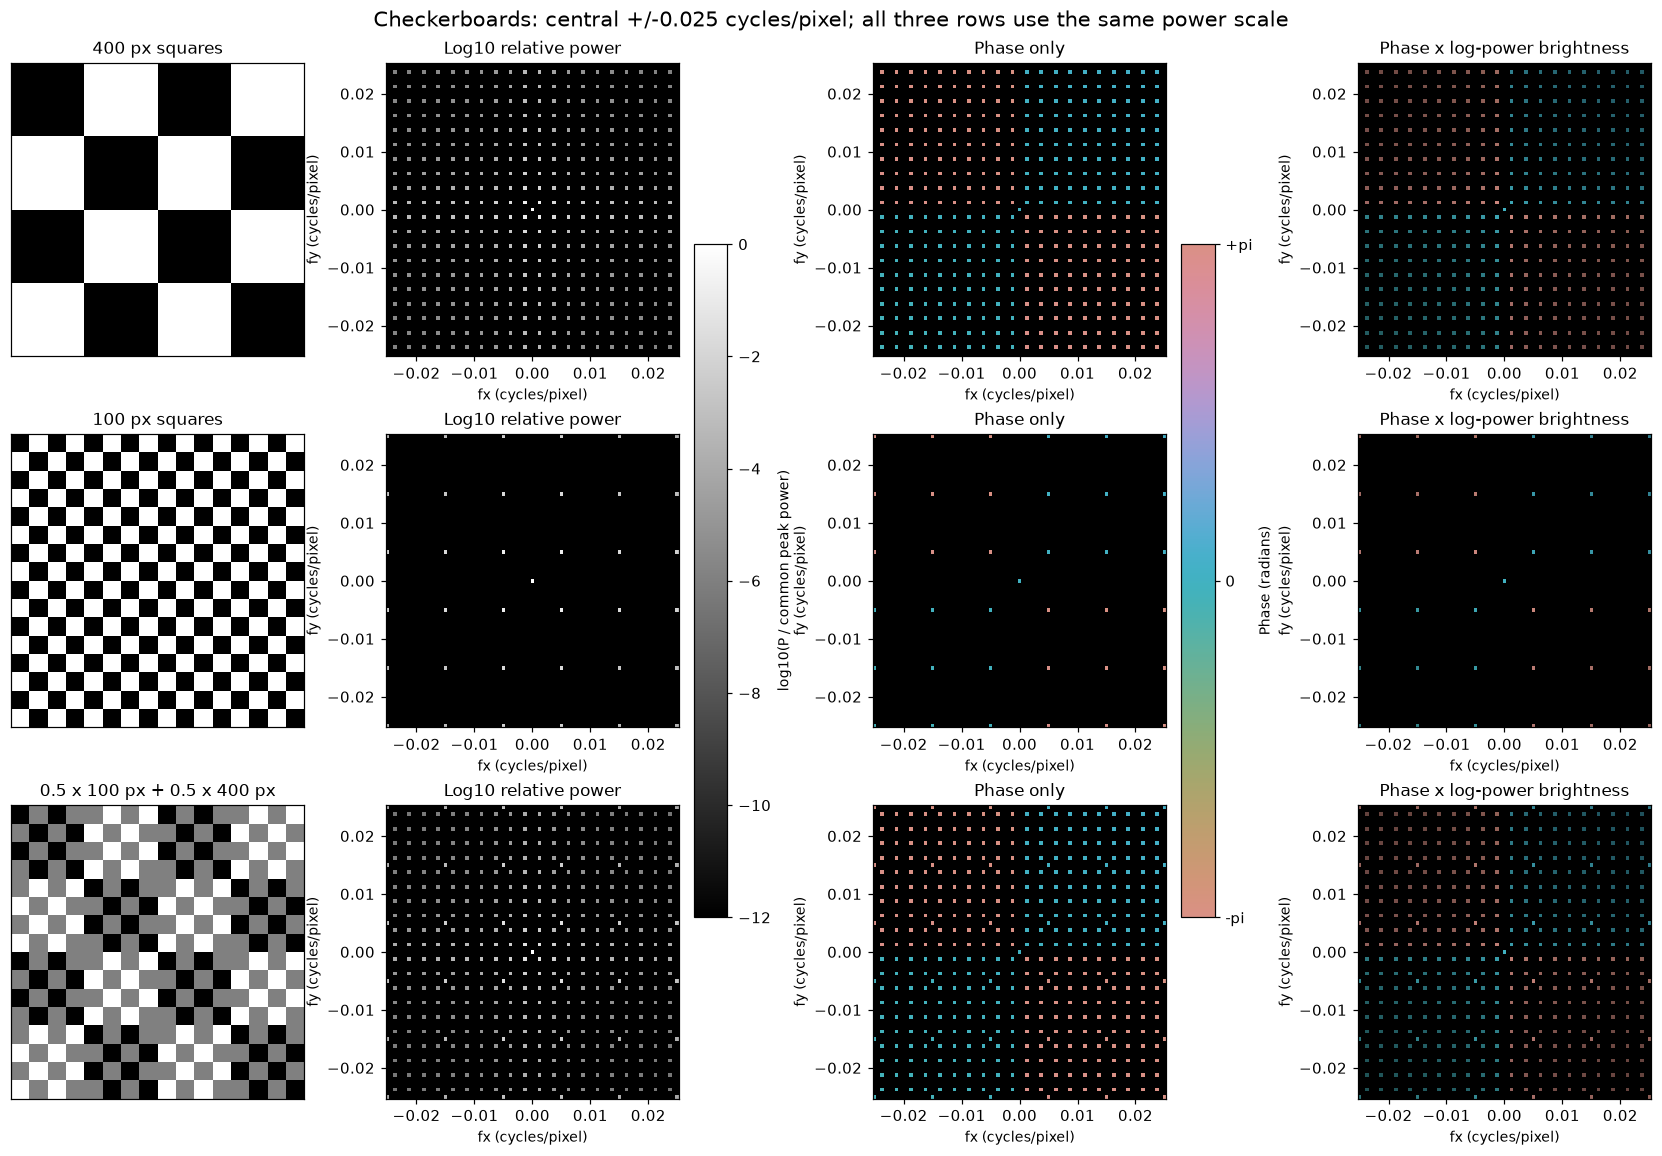

In [26]:
fig, axs = plt.subplots(3, 4, figsize=(15, 10.4), layout='constrained')
power_artist = None
for row, (name, a) in enumerate(boards.items()):
    v = board_views[name]
    show_photo(axs[row, 0], a)
    axs[row, 0].set_title(name)
    power_artist = show_frequency(axs[row, 1], v['log_power'], a.shape,
                                 CHECKER_ZOOM, cmap='gray', vmin=-POWER_DECADES, vmax=0)
    show_frequency(axs[row, 2], v['phase_rgb'], a.shape, CHECKER_ZOOM)
    show_frequency(axs[row, 3], v['blend'], a.shape, CHECKER_ZOOM)
    for col, title in enumerate(['Log10 relative power', 'Phase only', 'Phase x log-power brightness'], 1):
        axs[row, col].set_title(title)
fig.colorbar(power_artist, ax=list(axs[:, 1]), shrink=0.65,
             label='log10(P / common peak power)')
phase_bar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-np.pi, np.pi), cmap=PHASE_CMAP),
                        ax=list(axs[:, 2]), shrink=0.65, ticks=[-np.pi, 0, np.pi])
phase_bar.ax.set_yticklabels(['-pi', '0', '+pi'])
phase_bar.set_label('Phase (radians)')
view_label = 'full spectrum' if CHECKER_ZOOM is None else f'central +/-{CHECKER_ZOOM:g} cycles/pixel'
fig.suptitle(f'Checkerboards: {view_label}; all three rows use the same power scale', fontsize=14)
finish_figure(fig, '01_checkerboards_phase_power')

### Full frequency range

The close-up above makes the individual low-frequency peaks visible. The next figure shows the
full range out to the Nyquist limits. These spectra are sparse: on a reduced-size display a single-bin
peak can be hard to see. Zooming does not change the FFT or move its peaks.

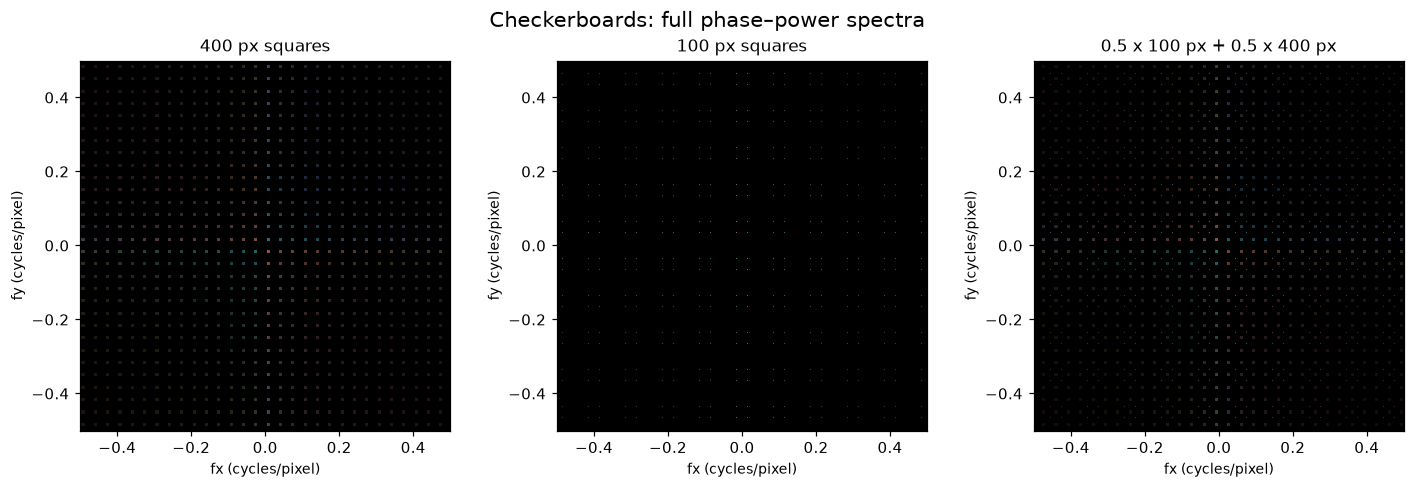

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3), layout='constrained')
for ax, (name, a) in zip(axs, boards.items()):
    show_frequency(ax, board_views[name]['blend'], a.shape)
    ax.set_title(name)
fig.suptitle('Checkerboards: full phase–power spectra', fontsize=14)
finish_figure(fig, '02_checkerboards_full_spectra')

## 4. A general photograph

The default photograph is embedded below so the notebook is self-contained. It is the CC0
“camera” image by Lav Varshney distributed with scikit-image. To substitute a photograph, set
`PHOTO_PATH` above and rerun from the settings cell. Colour inputs are converted to 8-bit display
greyscale; these values are image intensities, not calibrated radiance. Transparent pixels are
composited on white. No contrast stretching is applied.

In [28]:
# Embedded CC0 camera image, Lav Varshney / scikit-image. No network access needed.
SAMPLE_PNG_BASE64 = (
    '...'
)

In [29]:
if PHOTO_PATH is None:
    with Image.open(BytesIO(base64.b64decode(SAMPLE_PNG_BASE64))) as im:
        photo = pil_to_grey(im, PHOTO_MAX_SIDE)
    photo_name = 'Embedded camera photograph'
else:
    photo = read_grey(PHOTO_PATH, PHOTO_MAX_SIDE)
    photo_name = Path(PHOTO_PATH).name

F_photo = fft_image(photo)
photo_views = spectrum_views(F_photo)
photo_reference = photo_views['reference_power']
print(f'{photo_name}: {photo.shape[1]} x {photo.shape[0]} pixels')
print(f'Mean intensity: {photo.mean():.4f}; power reference: {photo_reference:.6g}')

Embedded camera photograph: 512 x 512 pixels
Mean intensity: 0.5061; power reference: 67150.3


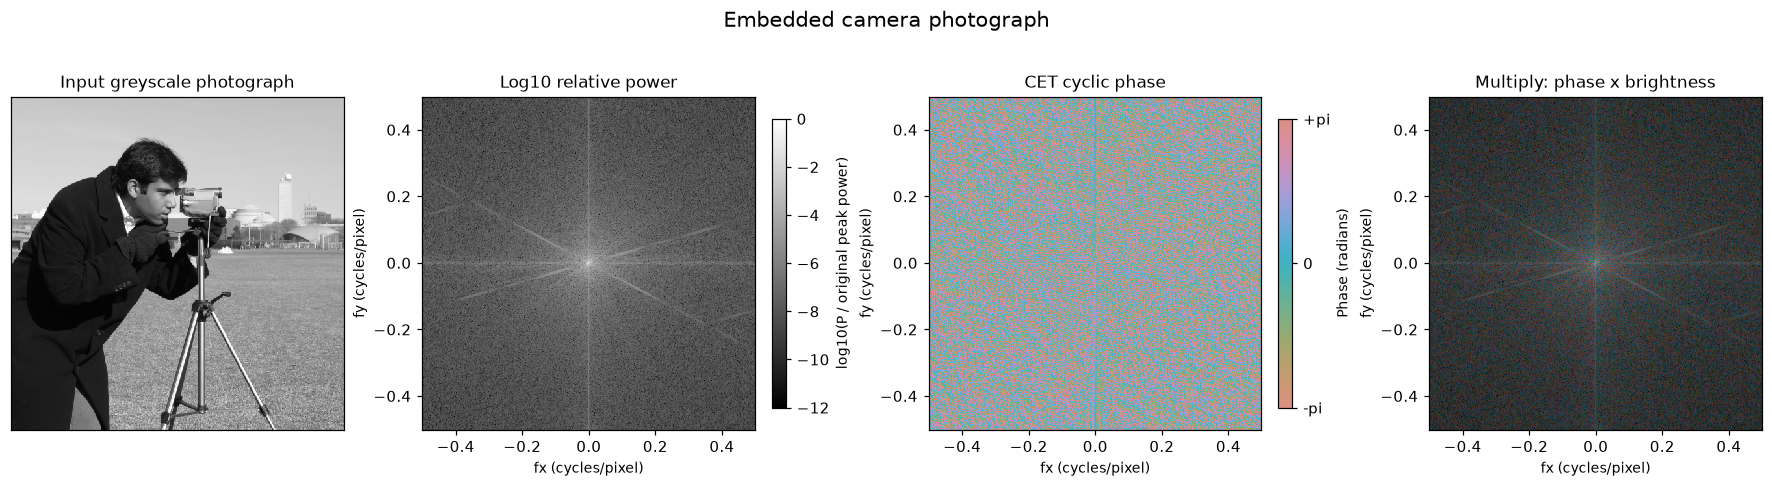

In [30]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4.4), layout='constrained')
show_photo(axs[0], photo)
axs[0].set_title('Input greyscale photograph')
im = show_frequency(axs[1], photo_views['log_power'], photo.shape,
                    cmap='gray', vmin=-POWER_DECADES, vmax=0)
axs[1].set_title('Log10 relative power')
show_frequency(axs[2], photo_views['phase_rgb'], photo.shape)
axs[2].set_title('CET cyclic phase')
show_frequency(axs[3], photo_views['blend'], photo.shape)
axs[3].set_title('Multiply: phase x brightness')
fig.colorbar(im, ax=axs[1], shrink=0.65, label='log10(P / original peak power)')
phase_bar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-np.pi, np.pi), cmap=PHASE_CMAP),
                        ax=axs[2], shrink=0.65, ticks=[-np.pi, 0, np.pi])
phase_bar.ax.set_yticklabels(['-pi', '0', '+pi'])
phase_bar.set_label('Phase (radians)')
fig.suptitle(photo_name, fontsize=14)
finish_figure(fig, '03_photo_phase_power')

## 5. Open a progressively wider window in frequency space

Imagine opening a square aperture over the centre of the FFT. At first only the central coefficient
passes: it gives a uniform image equal to the original mean. A wider aperture admits long-wavelength
variations, then progressively shorter-wavelength detail. When every coefficient passes, the original
image returns.

$$M_c(f_x,f_y)=\begin{cases}1,&|f_x|\leq c,\ |f_y|\leq c\\0,&\text{otherwise},\end{cases}
\qquad I_c=\operatorname{Re}\!\left\{\operatorname{IFFT2}
\left[\operatorname{ifftshift}(M_cF)\right]\right\}.$$

Here `c = 0.5 × fraction` cycles/pixel. The window is square **in frequency coordinates**; its bin
counts can differ on a non-square photograph. We retain the full-sized FFT array, set rejected
coefficients to zero, and invert it without resizing. The symmetric mask retains conjugate partners,
so the inverse stays real apart from round-off. We check that imaginary remainder before taking the real part.

Each following code cell is one stage. The first panel shows the passed phase–power spectrum and
a cyan window outline. Every stage uses the **original spectrum's power reference**.
The reconstruction always uses the greyscale limits **0–1**; its contrast is not rescaled per stage.
The error map always uses **0–1 absolute intensity error**.

**Two things to watch:**

- A hard-edged frequency window can create ripples near sharp boundaries (ringing).
- The FFT assumes that the image repeats outside its edges. Mismatched opposite edges can produce
  wrap-around effects. These are left visible here; a spatial taper would change the image being reconstructed.

Values outside 0–1 can occur after filtering. They remain in the reconstruction arrays and error
calculations, while the displayed greyscale clips them to black or white. The DC coefficient can
account for much of the total energy; the table also reports retained **variation energy** after excluding DC.

In [31]:
def frequency_window(shape, fraction):
    if not np.isfinite(fraction) or not 0 <= fraction <= 1:
        raise ValueError('fraction must be in [0, 1].')
    fx, fy = frequency_axes(shape)
    cutoff = 0.5 * fraction
    return (np.abs(fy[:, None]) <= cutoff) & (np.abs(fx[None, :]) <= cutoff)

def reconstruction_stats(F, original, fraction):
    mask = frequency_window(original.shape, fraction)
    filtered = F * mask
    complex_image = inverse_image(filtered)
    imag_max = float(np.abs(complex_image.imag).max())
    tolerance = 1e-10 * max(1.0, float(np.abs(complex_image).max()))
    if imag_max > tolerance:
        raise RuntimeError(f'Non-negligible imaginary component: {imag_max:g}')
    reconstructed = complex_image.real  # Do not use abs(): it would hide negative ringing.
    power = np.abs(F)**2
    non_dc = np.ones(original.shape, dtype=bool)
    non_dc[original.shape[0]//2, original.shape[1]//2] = False
    total_energy = float(power.sum())
    variation_energy = float(power[non_dc].sum())
    stats = dict(fraction=float(fraction), cutoff=0.5*fraction,
                 width=int(mask.any(axis=0).sum()), height=int(mask.any(axis=1).sum()),
                 bins_pct=100.0*mask.mean(),
                 energy_pct=100.0*power[mask].sum()/total_energy if total_energy else np.nan,
                 variation_pct=100.0*power[mask & non_dc].sum()/variation_energy
                               if variation_energy > 1e-24*max(1.0, total_energy) else np.nan,
                 rmse=float(np.sqrt(np.mean((reconstructed-original)**2))),
                 imag_max=imag_max, min=float(reconstructed.min()), max=float(reconstructed.max()))
    return mask, filtered, reconstructed, stats

def show_reconstruction_stage(index=None, fraction=None, export=True):
    if fraction is None:
        fraction = WINDOW_FRACTIONS[index]
    mask, filtered, reconstructed, stats = reconstruction_stats(F_photo, photo, fraction)
    # Reuse the ORIGINAL display RGB: rejected bins are black, retained bins keep their colour/brightness.
    filtered_rgb = photo_views['blend'] * mask[..., None]
    fig, axs = plt.subplots(1, 3, figsize=(12.6, 4.5), layout='constrained')
    show_frequency(axs[0], filtered_rgb, photo.shape)
    fx, fy = frequency_axes(photo.shape)
    kept_x, kept_y = fx[mask.any(axis=0)], fy[mask.any(axis=1)]
    x0, x1 = kept_x[0]-0.5/photo.shape[1], kept_x[-1]+0.5/photo.shape[1]
    y0, y1 = kept_y[0]-0.5/photo.shape[0], kept_y[-1]+0.5/photo.shape[0]
    axs[0].add_patch(Rectangle((x0,y0), x1-x0, y1-y0, fill=False,
                               edgecolor='#00ffff', linewidth=1.3))
    axs[0].set_title(f'Passed spectrum: {stats["width"]} x {stats["height"]} bins')
    show_photo(axs[1], reconstructed)
    axs[1].set_title('Reconstruction (fixed greyscale 0–1)')
    err = axs[2].imshow(np.abs(reconstructed-photo), cmap='magma', vmin=0, vmax=1,
                        origin='upper', interpolation='nearest')
    axs[2].set_xticks([])
    axs[2].set_yticks([])
    axs[2].set_title(f'Absolute error; RMSE = {stats["rmse"]:.5f}')
    fig.colorbar(err, ax=axs[2], shrink=0.7, label='Absolute intensity error')
    label = 'DC only' if fraction == 0 else ('All frequencies' if fraction == 1
                                              else f'{fraction:.4g} x Nyquist half-width')
    fig.suptitle(f'{label} | cutoff +/-{stats["cutoff"]:.5g} cycles/pixel | '
                 f'{stats["energy_pct"]:.2f}% total energy retained', fontsize=13)
    if export:
        suffix = f'stage_{index+1:02d}' if index is not None else f'fraction_{fraction:.5f}'
        finish_figure(fig, '04_reconstruction_' + suffix)
    else:
        plt.show()
        plt.close(fig)
    print(f'Intensity range [{stats["min"]:.5f}, {stats["max"]:.5f}]; '
          f'max |imaginary part| = {stats["imag_max"]:.2e}; '
          f'variation energy retained = {stats["variation_pct"]:.2f}%')
    return stats

### Stage 1: DC only

One coefficient remains. The entire image becomes its average intensity.

The numerical cutoff is set by `WINDOW_FRACTIONS[0]`.

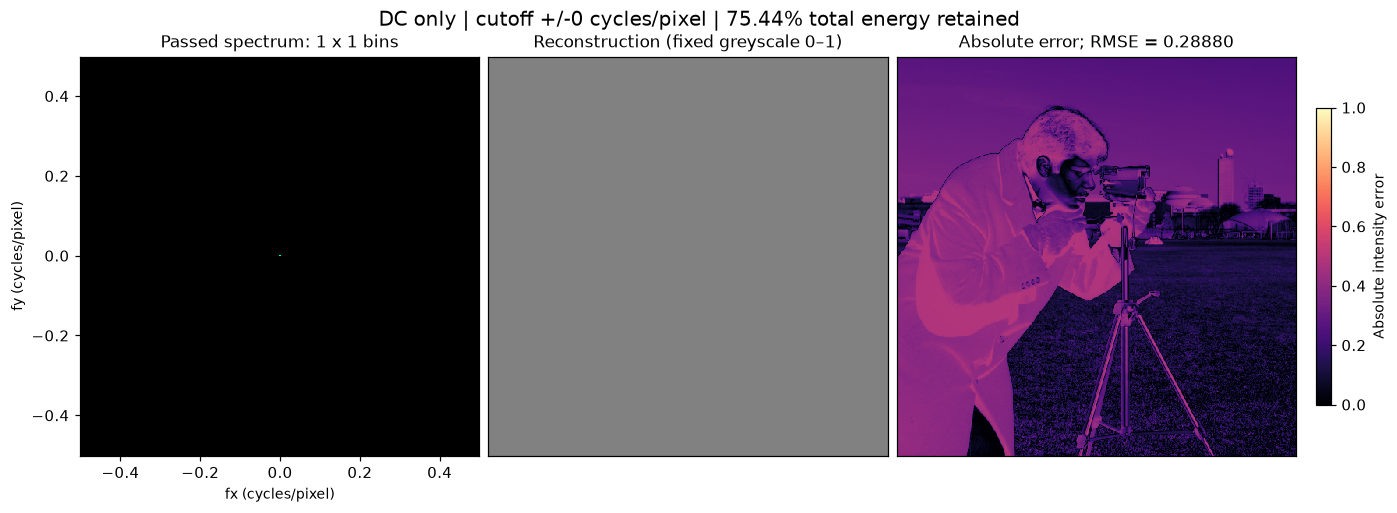

Intensity range [0.50612, 0.50612]; max |imaginary part| = 0.00e+00; variation energy retained = 0.00%


In [32]:
stage_01 = show_reconstruction_stage(index=0)

### Stage 2: A very narrow window

Only broad changes in brightness enter the reconstruction.

The numerical cutoff is set by `WINDOW_FRACTIONS[1]`.

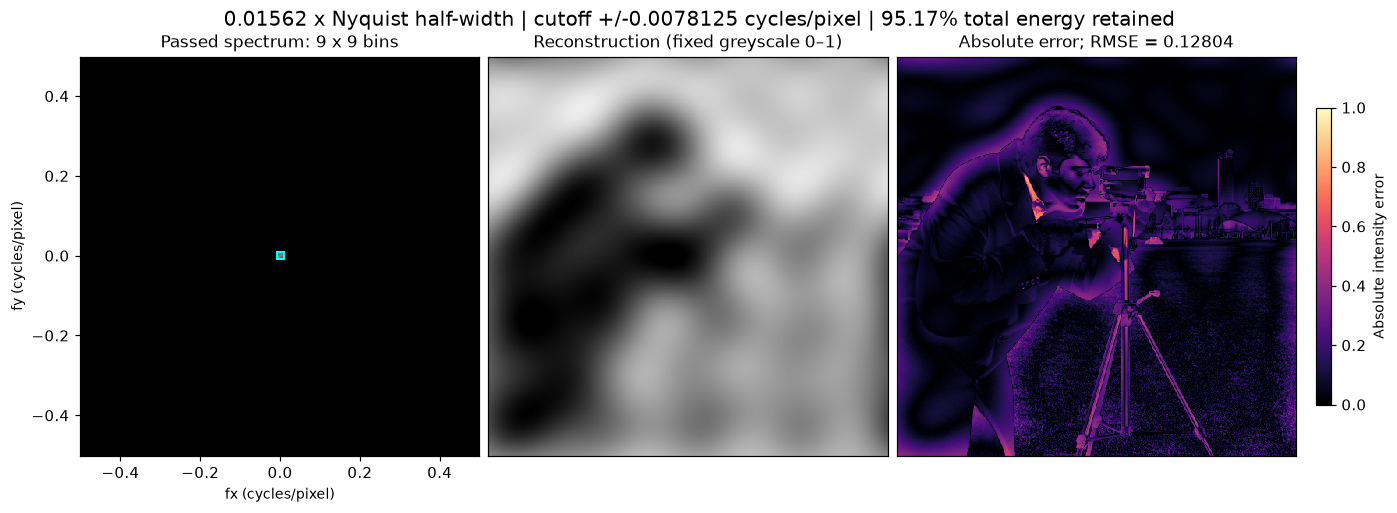

Intensity range [-0.03737, 0.92915]; max |imaginary part| = 3.17e-16; variation energy retained = 80.34%


In [33]:
stage_02 = show_reconstruction_stage(index=1)

### Stage 3: A wider window

Large forms become clearer as more spatial frequencies pass.

The numerical cutoff is set by `WINDOW_FRACTIONS[2]`.

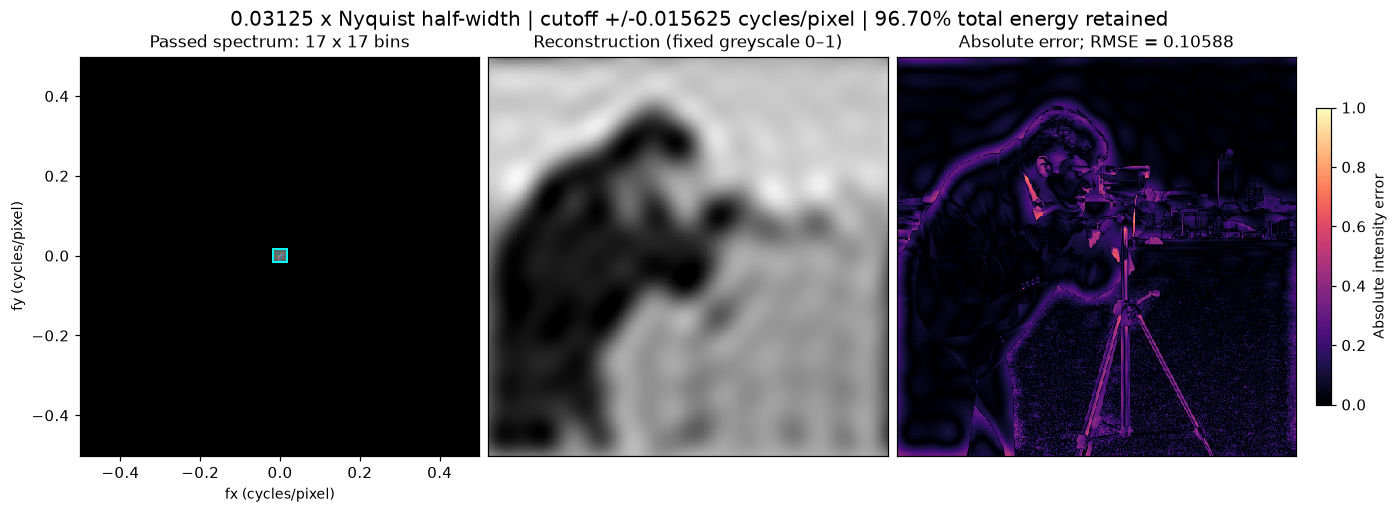

Intensity range [-0.04974, 0.97294]; max |imaginary part| = 3.32e-16; variation energy retained = 86.56%


In [34]:
stage_03 = show_reconstruction_stage(index=2)

### Stage 4: More detail

Intermediate-scale structure begins to sharpen.

The numerical cutoff is set by `WINDOW_FRACTIONS[3]`.

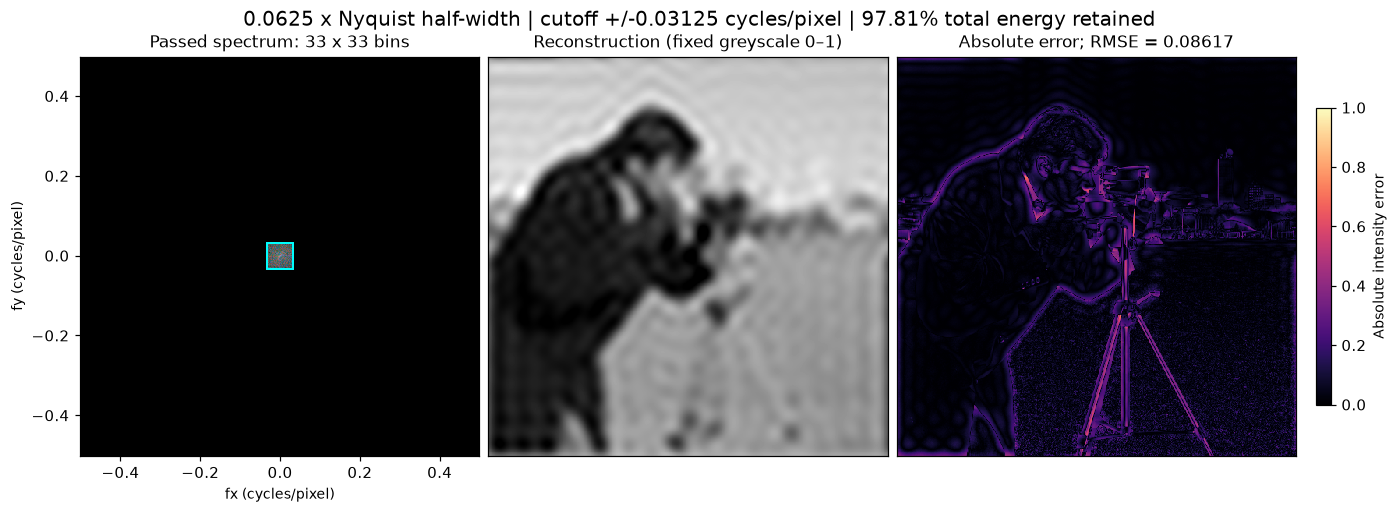

Intensity range [-0.12991, 1.02145]; max |imaginary part| = 3.20e-16; variation energy retained = 91.10%


In [35]:
stage_04 = show_reconstruction_stage(index=3)

### Stage 5: Opening farther

Shorter waves add sharper edges and texture.

The numerical cutoff is set by `WINDOW_FRACTIONS[4]`.

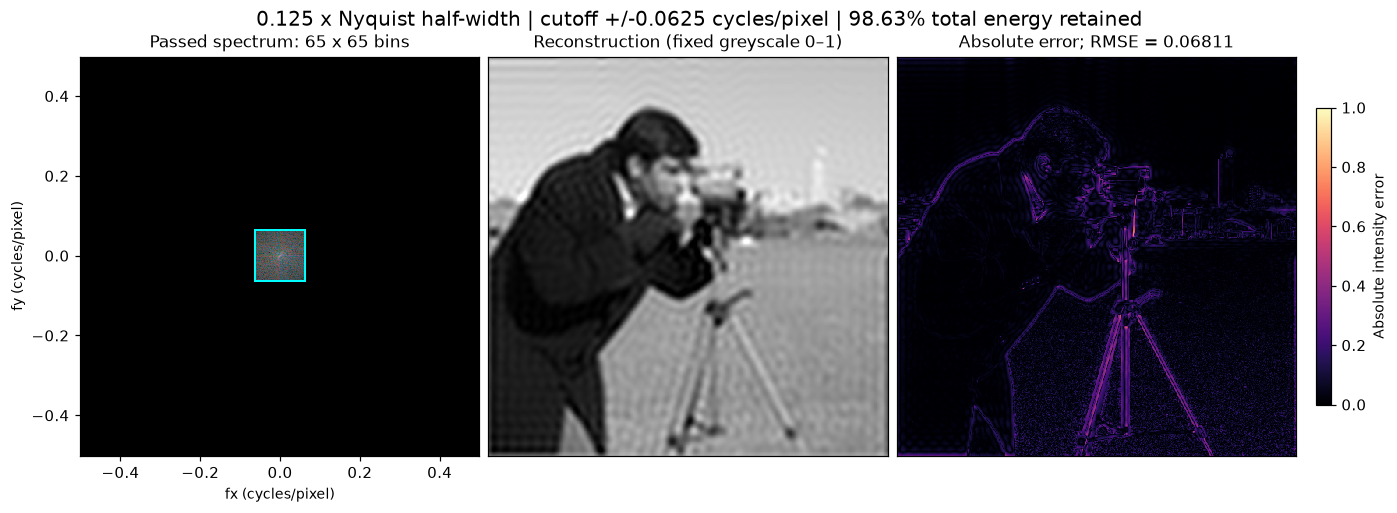

Intensity range [-0.11127, 1.07424]; max |imaginary part| = 3.49e-16; variation energy retained = 94.44%


In [36]:
stage_05 = show_reconstruction_stage(index=4)

### Stage 6: A quarter of the Nyquist half-width

Compare the recovered detail and any ringing near edges.

The numerical cutoff is set by `WINDOW_FRACTIONS[5]`.

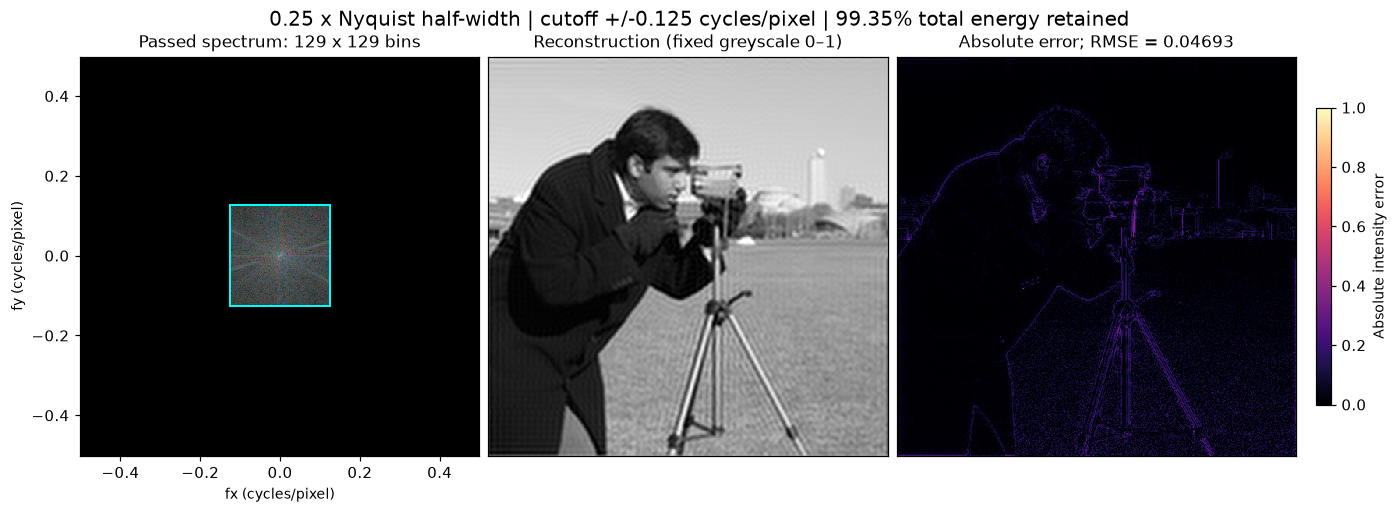

Intensity range [-0.08744, 1.13180]; max |imaginary part| = 3.75e-16; variation energy retained = 97.36%


In [37]:
stage_06 = show_reconstruction_stage(index=5)

### Stage 7: Half of the Nyquist half-width

Fine detail returns, although some high frequencies remain excluded.

The numerical cutoff is set by `WINDOW_FRACTIONS[6]`.

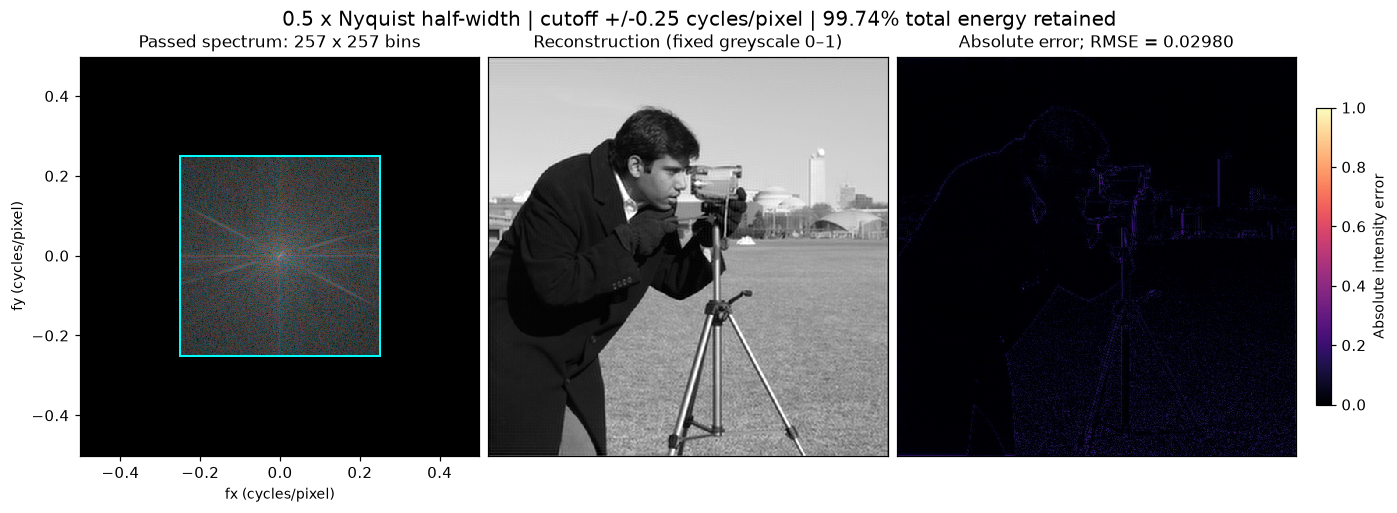

Intensity range [-0.06041, 1.09252]; max |imaginary part| = 4.00e-16; variation energy retained = 98.94%


In [38]:
stage_07 = show_reconstruction_stage(index=6)

### Stage 8: The full spectrum

Every coefficient passes. The reconstruction should match the input to numerical precision.

The numerical cutoff is set by `WINDOW_FRACTIONS[7]`.

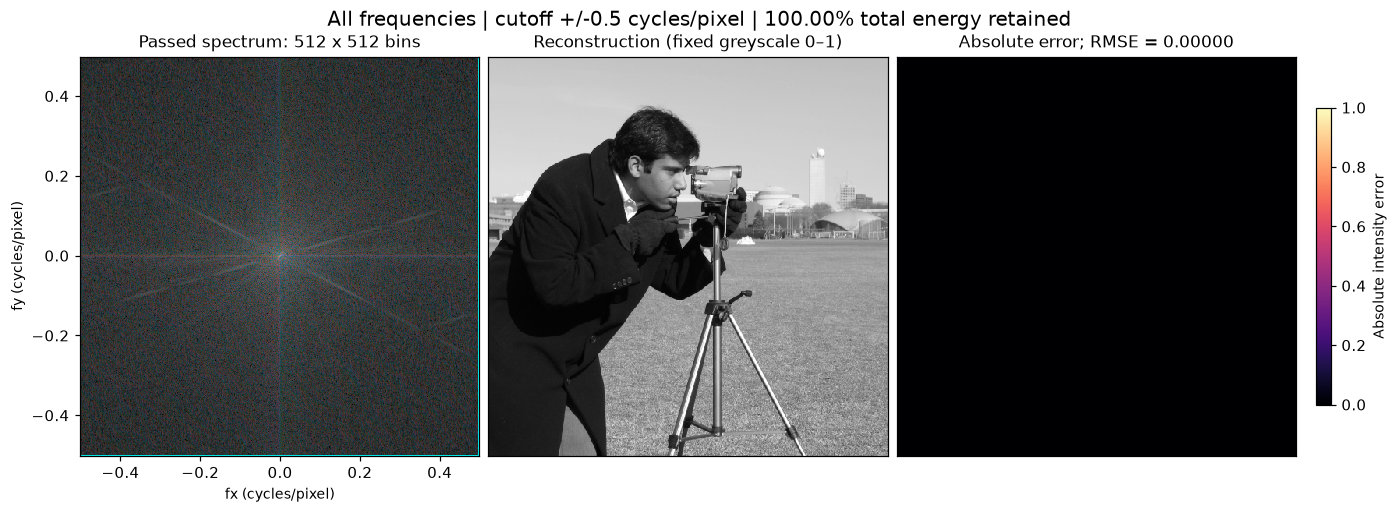

Intensity range [0.00000, 1.00000]; max |imaginary part| = 4.86e-16; variation energy retained = 100.00%


In [39]:
stage_08 = show_reconstruction_stage(index=7)

## 6. Compare all eight reconstructions

Read left to right, then continue on the second row. A larger pass window increases the number of
waves available to reproduce the original. RMSE is measured against the input on the 0–1 intensity
scale; it is not a percentage or a measure of visual similarity. The percentage columns refer to
frequency-bin counts or squared-intensity energy, as labelled.

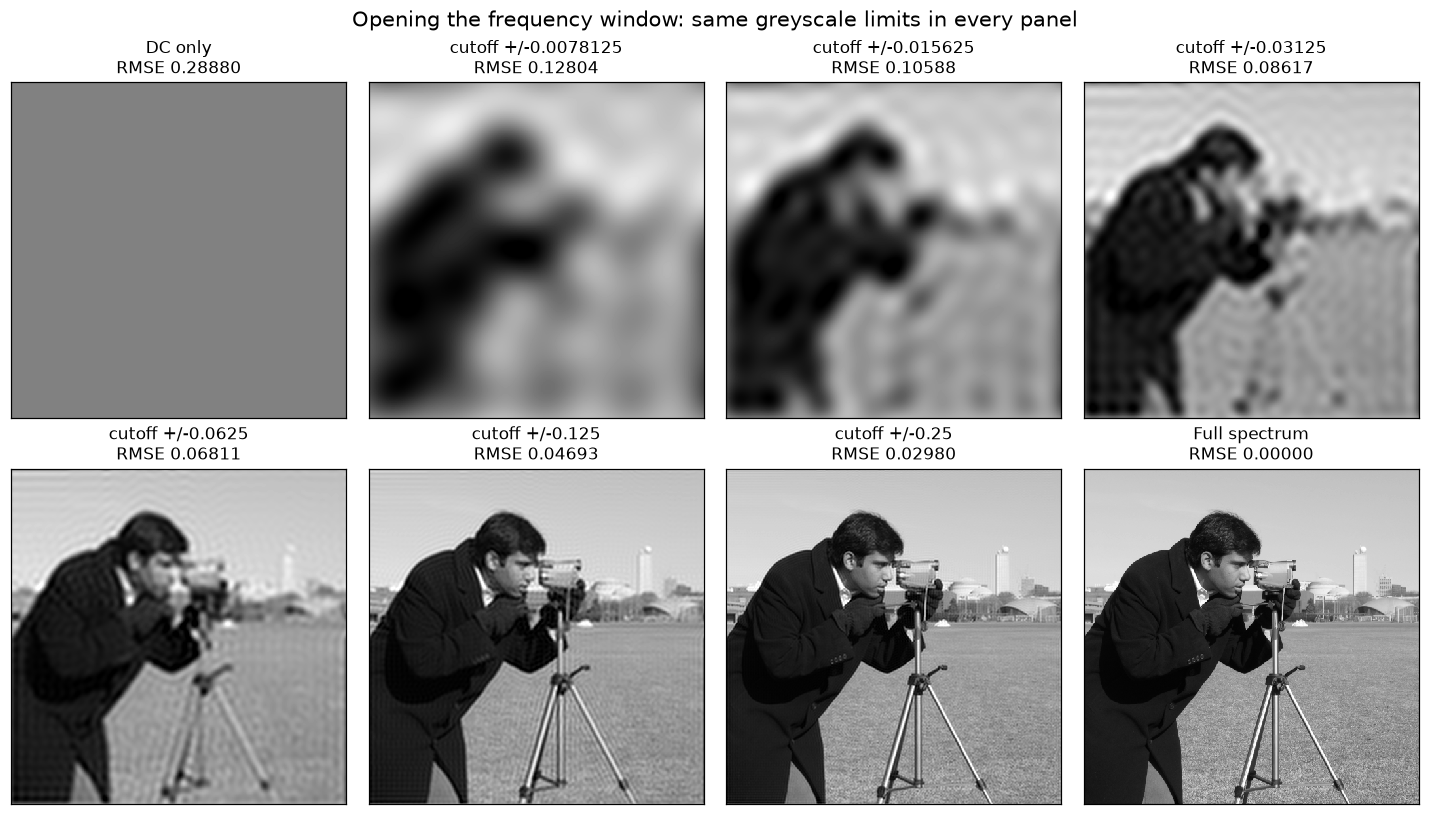

| Stage | Half-width / Nyquist | Window (x × y bins) | Bins (%) | Total energy (%) | Variation energy (%) | RMSE |
|---|---:|---:|---:|---:|---:|---:|
| 1 | 0 | 1 × 1 | 0.000 | 75.437 | 0.000 | 0.2888033 |
| 2 | 0.015625 | 9 × 9 | 0.031 | 95.172 | 80.344 | 0.1280424 |
| 3 | 0.03125 | 17 × 17 | 0.110 | 96.699 | 86.559 | 0.1058801 |
| 4 | 0.0625 | 33 × 33 | 0.415 | 97.813 | 91.098 | 0.0861664 |
| 5 | 0.125 | 65 × 65 | 1.612 | 98.634 | 94.438 | 0.0681097 |
| 6 | 0.25 | 129 × 129 | 6.348 | 99.351 | 97.360 | 0.0469267 |
| 7 | 0.5 | 257 × 257 | 25.196 | 99.739 | 98.936 | 0.0297954 |
| 8 | 1 | 512 × 512 | 100.000 | 100.000 | 100.000 | 0.0000000 |

In [40]:
fig, axs = plt.subplots(2, 4, figsize=(13, 7.3), layout='constrained')
summary_stats = []
for ax, fraction in zip(axs.flat, WINDOW_FRACTIONS):
    _, _, rec, stats = reconstruction_stats(F_photo, photo, fraction)
    summary_stats.append(stats)
    show_photo(ax, rec)
    label = 'DC only' if fraction == 0 else ('Full spectrum' if fraction == 1 else f'cutoff +/-{stats["cutoff"]:g}')
    ax.set_title(f'{label}\nRMSE {stats["rmse"]:.5f}')
fig.suptitle('Opening the frequency window: same greyscale limits in every panel', fontsize=14)
finish_figure(fig, '05_reconstruction_contact_sheet')

rows = ['| Stage | Half-width / Nyquist | Window (x × y bins) | Bins (%) | Total energy (%) | Variation energy (%) | RMSE |',
        '|---|---:|---:|---:|---:|---:|---:|']
for i, s in enumerate(summary_stats):
    rows.append(f'| {i+1} | {s["fraction"]:.5g} | {s["width"]} × {s["height"]} '
                f'| {s["bins_pct"]:.3f} | {s["energy_pct"]:.3f} '
                f'| {s["variation_pct"]:.3f} | {s["rmse"]:.7f} |')
display(Markdown('\n'.join(rows)))

## 7. Numerical checks

These checks verify the two endpoints, energy conservation, and the expected decline in squared
error for nested ideal windows. The full reconstruction is compared to the **loaded greyscale image**,
after any configured resizing or colour conversion.

In [41]:
full = inverse_image(F_photo)
max_error = float(np.max(np.abs(full.real-photo)))
energy_space = float(np.sum(photo**2))
energy_fft = float(np.sum(np.abs(F_photo)**2))
dc_mask, _, dc_image, _ = reconstruction_stats(F_photo, photo, 0)
full_mask = frequency_window(photo.shape, 1)
errors = np.array([s['rmse'] for s in summary_stats])
np.testing.assert_allclose(full.real, photo, atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(energy_fft, energy_space, atol=1e-10, rtol=1e-12)
np.testing.assert_allclose(dc_image, photo.mean(), atol=1e-12)
assert dc_mask.sum() == 1, 'The first window should retain exactly one DC bin.'
assert full_mask.all(), 'The final window must retain all bins, including Nyquist.'
assert np.all(np.diff(errors) <= 1e-12), 'Error should not increase for nested orthogonal windows.'
# Parseval also predicts the reconstruction error directly from discarded coefficient power.
for fraction, observed_rmse in zip(WINDOW_FRACTIONS, errors):
    mask = frequency_window(photo.shape, fraction)
    predicted_rmse = np.sqrt(np.sum(np.abs(F_photo[~mask])**2)/photo.size)
    np.testing.assert_allclose(observed_rmse, predicted_rmse, atol=1e-12)
print(f'Full inverse: maximum pixel error = {max_error:.3e}')
print(f'Parseval energy: image {energy_space:.8f}; FFT {energy_fft:.8f}')
print('PASS: full inverse, DC-only mean, all-frequency mask, and nested-window error checks.')

Full inverse: maximum pixel error = 1.110e-15
Parseval energy: image 89015.00935025; FFT 89015.00935025
PASS: full inverse, DC-only mean, all-frequency mask, and nested-window error checks.


## 8. Optional live slider

This is a convenience for live teaching; the eight stages above work without widgets.
Install `ipywidgets` if needed. The slider redraws only after you release it. It does not save figures.

In [ ]:
try:
    import ipywidgets as widgets
except ImportError:
    print('Optional slider unavailable. Install with: %pip install ipywidgets')
else:
    slider = widgets.FloatSlider(value=0.125, min=0, max=1, step=1/512,
                                 description='Half-width:', readout_format='.3f',
                                 continuous_update=False,
                                 style={'description_width': 'initial'},
                                 layout=widgets.Layout(width='75%'))
    def redraw(fraction):
        show_reconstruction_stage(fraction=fraction, export=False)
    slider_output = widgets.interactive_output(redraw, {'fraction': slider})
    display(widgets.VBox([slider, slider_output]))

## Teaching prompts and references

1. Why are the 100 px pattern's main peaks farther from the centre than the 400 px pattern's peaks?
2. Why does a sharp checkerboard need more than one spatial frequency?
3. Why does DC alone give the mean brightness rather than a black image?
4. Which structures return first as the frequency window widens?
5. How much total energy is retained before recognisable detail appears? Compare variation energy.
6. What happens to the phase colours if you shift a checkerboard by a few pixels without changing its squares?

The FFT represents the sampled greyscale intensities, with pixel spacing set to one. Axis labels are
cycles/pixel, and the maximum absolute sampled frequency is at most 0.5 cycles/pixel. Image translation
changes phase; taking the magnitude of the inverse FFT would alter negative ringing, so the code uses its real part.

- [NumPy: FFT definitions, amplitude, power, phase, normalisation and symmetry](https://numpy.org/doc/stable/reference/routines.fft.html)
- [Colorcet: CET continuous and cyclic colourmaps](https://colorcet.holoviz.org/user_guide/Continuous.html)
- [scikit-image: camera image and CC0 attribution](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.camera)

**Export:** set `EXPORT_FIGURES = True` and rerun the plot cells to save PNGs in `fft_demo_output`.
For reconstructions, retain the float arrays for analysis; a displayed image can clip ringing outside 0–1.